# For Classification:

## Accuracy
The most straightforward metric. It measures the overall correctness of the model's predictions.  Calculated as: (Number of correct predictions) / (Total number of predictions).

Advantages: Easy to understand and interpret.
Disadvantages: Can be misleading if the classes are imbalanced (e.g., one class has many more examples than others).
## Precision
Measures how many of the positive predictions were actually correct.  It focuses on the quality of positive predictions. Calculated as: (Number of true positives) / (Number of true positives + Number of false positives).

Advantages: Useful when minimizing false positives is important (e.g., spam detection).
Disadvantages: Doesn't consider false negatives. A model with high precision might miss many actual positive cases.
## Recall (Sensitivity or True Positive Rate)
Measures how many of the actual positive cases were correctly predicted.  It focuses on the model's ability to find all the positives. Calculated as: (Number of true positives) / (Number of true positives + Number of false negatives).

Advantages: Useful when minimizing false negatives is crucial (e.g., disease detection).
Disadvantages: Doesn't consider false positives. A model with high recall might have many false positives.
## F1-score
The harmonic mean of precision and recall. It provides a balanced measure that considers both false positives and false negatives. Calculated as: 2 * (Precision * Recall) / (Precision + Recall).   

Advantages: Useful when you want a good balance between precision and recall.
Disadvantages: Not as interpretable as precision or recall alone.
## AUC (Area Under the ROC Curve)
Measures the ability of the classifier to distinguish between classes at different thresholds.  It plots the True Positive Rate (Recall) against the False Positive Rate at various thresholds.  An AUC of 1 is perfect, and 0.5 is random chance.

Advantages: Less sensitive to class imbalance than accuracy. Provides a good overall measure of performance.
Disadvantages: Can be less intuitive than other metrics.
## Confusion Matrix
A table that summarizes the model's predictions. It shows the counts of true positives, true negatives, false positives, and false negatives.

Advantages: Provides a complete picture of the model's performance, showing where it makes mistakes.
Disadvantages: Can be a bit overwhelming for quick comparisons, especially with many classes.
## Classification Report
A summary that includes precision, recall, F1-score, and support (number of samples) for each class. Often presented alongside the confusion matrix.

## Log Loss (Cross-Entropy Loss)
A common loss function used in classification.  It measures the difference between the predicted probability distribution and the true distribution.  Lower log loss is better.  It is often used during training as well as for evaluation.

# For Regression:

## Mean Squared Error (MSE)
The average of the squared differences between the predicted and actual values.  Sensitive to outliers.  Lower MSE is better.

## Root Mean Squared Error (RMSE)
The square root of the MSE.  It's in the same units as the target variable, making it easier to interpret. Lower RMSE is better.

## Mean Absolute Error (MAE)
The average of the absolute differences between the predicted and actual values.  Less sensitive to outliers than MSE. Lower MAE is better.

## R-squared (Coefficient of Determination)
Measures the proportion of the variance in the target variable that is predictable from the features.  Usually ranges from 0 to 1 (it can go negative when a model is worse than predicting the mean).  Higher R-squared is better.   

# Other Important Considerations

## Class Imbalance
If your classes are imbalanced, choose metrics that are less sensitive to this issue, such as AUC, F1-score (with appropriate averaging), or look at the metrics for each class individually.
## Business Goals
The best metric ultimately depends on your specific business goals. For example, if minimizing false positives is critical, you might prioritize precision.
## Context
Consider the context of your problem. What are the costs associated with different types of errors (false positives vs. false negatives)? This will help you choose the most relevant metric.
## Multiple Metrics
It's often a good idea to consider multiple metrics to get a well-rounded view of your model's performance.
Remember to choose the metrics that best align with your specific task and objectives. Don't rely on just one metric; consider a combination for a more comprehensive evaluation.

# Example: Diabetes Classification

Load the data and keep the numeric clinical features.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("Data/diabetes.csv")
df = df.drop(['year','gender','location','clinical_notes', 'smoking_history',
              'race:AfricanAmerican','race:Asian','race:Caucasian','race:Hispanic','race:Other'], axis=1)
df.describe()

,age,hypertension,heart_disease,bmi,hbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


## Check the class balance first
Only about 8.5% of patients have diabetes. A model that **always** predicts "no diabetes" scores ~91.5% accuracy
while finding zero diabetic patients - exactly the trap described under *Accuracy* and *Class Imbalance* above.

In [2]:
X = df.drop(columns='diabetes').to_numpy()
y = df['diabetes'].to_numpy()

print(X.shape, y.shape)
print(df['diabetes'].value_counts(normalize=True))

(100000, 6) (100000,)
diabetes
0    0.915
1    0.085
Name: proportion, dtype: float64


In [3]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
                             classification_report, roc_curve, roc_auc_score, log_loss)

keras.utils.set_random_seed(42)

# stratify keeps the 8.5% positive rate the same in train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Neural nets train poorly on unscaled features (age ~40, glucose ~140, flags 0/1).
# Fit the scaler on training data only so no test information leaks in.
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [4]:
# Baseline: always predict the majority class
y_baseline = np.zeros_like(y_test)
print(f"Baseline accuracy: {accuracy_score(y_test, y_baseline):.4f}")
print(f"Baseline recall:   {recall_score(y_test, y_baseline):.4f}")

Baseline accuracy: 0.9150
Baseline recall:   0.0000


In [5]:
# Define the model (single sigmoid output = probability of diabetes)
model = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy', keras.metrics.AUC(name='auc')])

# Stop when validation loss stops improving and keep the best weights
early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
history = model.fit(X_train, y_train, epochs=30, batch_size=256, validation_split=0.2,
                    callbacks=[early_stop], verbose=2)

Epoch 1/30


250/250 - 1s - 5ms/step - accuracy: 0.9231 - auc: 0.8550 - loss: 0.2283 - val_accuracy: 0.9568 - val_auc: 0.9603 - val_loss: 0.1203


Epoch 2/30


250/250 - 0s - 1ms/step - accuracy: 0.9557 - auc: 0.9519 - loss: 0.1265 - val_accuracy: 0.9605 - val_auc: 0.9632 - val_loss: 0.1127


Epoch 3/30


250/250 - 0s - 1ms/step - accuracy: 0.9595 - auc: 0.9558 - loss: 0.1185 - val_accuracy: 0.9626 - val_auc: 0.9650 - val_loss: 0.1084


... (50 outputs left out)

Epoch 29/30


250/250 - 0s - 2ms/step - accuracy: 0.9720 - auc: 0.9751 - loss: 0.0829 - val_accuracy: 0.9701 - val_auc: 0.9744 - val_loss: 0.0850


Epoch 30/30


250/250 - 0s - 1ms/step - accuracy: 0.9720 - auc: 0.9745 - loss: 0.0834 - val_accuracy: 0.9701 - val_auc: 0.9747 - val_loss: 0.0848


## Evaluate
With a single sigmoid output, `predict` returns one probability per row. Convert it to a class with a
**threshold** (0.5 by default). `np.argmax(..., axis=1)` would always return 0 here because there is only one column.

In [6]:
y_pred_probs = model.predict(X_test, verbose=0).ravel()
y_pred = (y_pred_probs >= 0.5).astype(int)

# For a binary problem report metrics for the positive (diabetes) class
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred):.4f}")
print(f"ROC AUC:   {roc_auc_score(y_test, y_pred_probs):.4f}")
print(f"Log loss:  {log_loss(y_test, y_pred_probs):.4f}")
print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred)}")
print(f"Classification Report:\n{classification_report(y_test, y_pred, target_names=['no diabetes', 'diabetes'])}")

Accuracy:  0.9723
Precision: 0.9974
Recall:    0.6759
F1-score:  0.8058
ROC AUC:   0.9761
Log loss:  0.0820
Confusion Matrix:
[[18297     3]
 [  551  1149]]
Classification Report:
              precision    recall  f1-score   support

 no diabetes       0.97      1.00      0.99     18300
    diabetes       1.00      0.68      0.81      1700

    accuracy                           0.97     20000
   macro avg       0.98      0.84      0.90     20000
weighted avg       0.97      0.97      0.97     20000



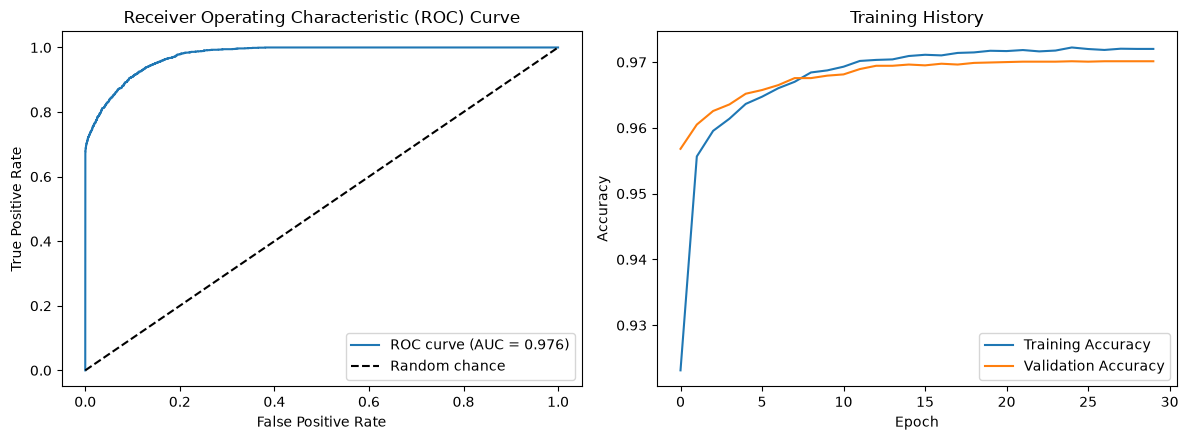

In [7]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_probs)
roc_auc = roc_auc_score(y_test, y_pred_probs)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.3f})')
ax1.plot([0, 1], [0, 1], 'k--', label='Random chance')
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.set_title('Receiver Operating Characteristic (ROC) Curve')
ax1.legend(loc="lower right")

ax2.plot(history.history['accuracy'], label='Training Accuracy')
ax2.plot(history.history['val_accuracy'], label='Validation Accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.set_title('Training History')
ax2.legend()
plt.tight_layout()
plt.show()

## Choosing the threshold is a business decision
Lowering the threshold catches more diabetic patients (higher recall) at the cost of more false alarms (lower precision).
For disease screening a missed case is usually more costly than a follow-up test, so a lower threshold may be preferred.

In [8]:
rows = []
for t in [0.1, 0.2, 0.3, 0.5, 0.7]:
    p = (y_pred_probs >= t).astype(int)
    rows.append({'threshold': t,
                 'precision': precision_score(y_test, p, zero_division=0),
                 'recall': recall_score(y_test, p),
                 'f1': f1_score(y_test, p),
                 'false_positives': int(((p == 1) & (y_test == 0)).sum()),
                 'missed_cases': int(((p == 0) & (y_test == 1)).sum())})
pd.DataFrame(rows).round(3)

,threshold,precision,recall,f1,false_positives,missed_cases
0,0.1,0.485,0.894,0.629,1613,180
1,0.2,0.745,0.779,0.762,453,376
2,0.3,0.915,0.721,0.806,114,475
3,0.5,0.997,0.676,0.806,3,551
4,0.7,1.000,0.674,0.805,0,554


# Example: Regression Metrics
Uses scikit-learn's built-in diabetes progression dataset (target = disease progression one year after baseline).

In [9]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

Xr, yr = load_diabetes(return_X_y=True)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.2, random_state=42)

reg = LinearRegression().fit(Xr_train, yr_train)
yr_pred = reg.predict(Xr_test)

mse = mean_squared_error(yr_test, yr_pred)
print(f"MSE:  {mse:.1f}")
print(f"RMSE: {np.sqrt(mse):.1f}   (same units as the target, which ranges {yr.min():.0f}-{yr.max():.0f})")
print(f"MAE:  {mean_absolute_error(yr_test, yr_pred):.1f}")
print(f"R^2:  {r2_score(yr_test, yr_pred):.3f}")

# Baseline: always predict the training mean -> R^2 near 0
print(f"Baseline R^2: {r2_score(yr_test, np.full_like(yr_test, yr_train.mean())):.3f}")

MSE:  2900.2
RMSE: 53.9   (same units as the target, which ranges 25-346)
MAE:  42.8
R^2:  0.453
Baseline R^2: -0.012
